ACQUAINTANCES CONSPIRACY SCORES



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102037 entries, 0 to 102036
Data columns (total 3 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   author            102037 non-null  object 
 1   subreddits        102037 non-null  object 
 2   conspiracy_score  102037 non-null  float64
dtypes: float64(1), object(2)
memory usage: 2.3+ MB
None


         author                                         subreddits  \
0     geiger253  [{'subreddit': 'reddit.com', 'count': 335}, {'...   
1      morituri  [{'subreddit': 'reddit.com', 'count': 95}, {'s...   
2  downdiagonal  [{'subreddit': 'reddit.com', 'count': 3}, {'su...   
3   jaggederest  [{'subreddit': 'reddit.com', 'count': 1847}, {...   
4     otakucode  [{'subreddit': 'reddit.com', 'count': 2814}, {...   

   conspiracy_score  
0         -0.101575  
1         -0.030149  
2         -0.204984  
3         -0.192808  
4         -0.141335  


            author                

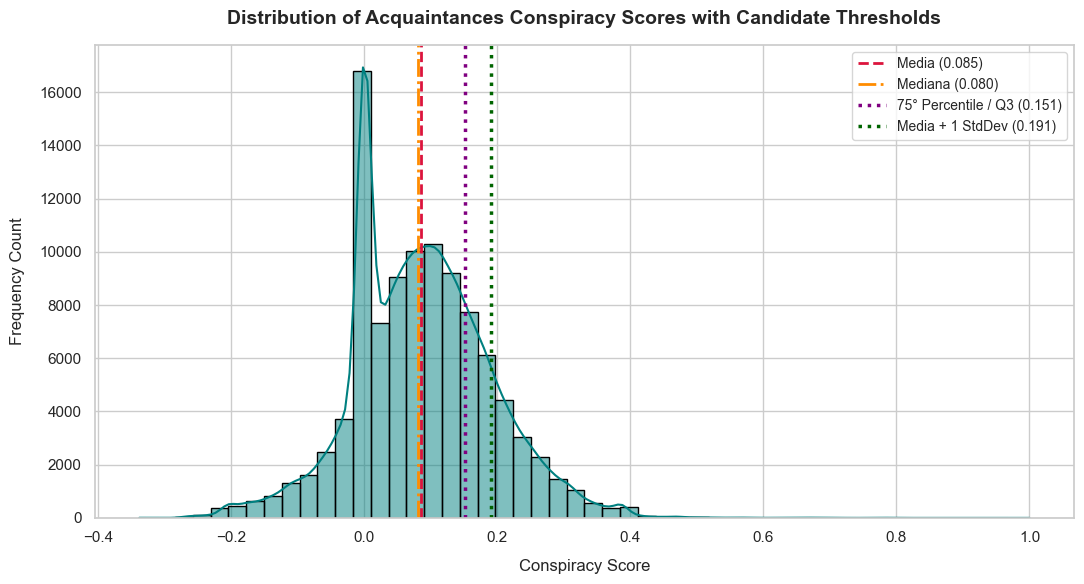

In [4]:
import pandas as pd
import matplotlib.pyplot as plt  # Corretto l'import per pyplot
import seaborn as sns
import json
import numpy as np
import os


founders_folder_path = "../data/raw/FOUNDERS_DATA/"

matching_dict_path = "../data/interim/matching_dict_optimized.json"
with open(matching_dict_path, "r") as f:
    matching_dict = json.load(f)
    
# Collect founder usernames
anchors = [anchor for anchor in matching_dict.keys()]
candidates = [candidate["candidate"] for candidate in matching_dict.values()]
founders = anchors + candidates

dfs = list()

for f in founders:
    founder_path = f + "_data/"
    acquaintances_scores_path = f + "_acquaintancesScores.csv"

    full_path = os.path.join(founders_folder_path, founder_path, acquaintances_scores_path)

    if os.path.exists(full_path):
        df = pd.read_csv(full_path)
        dfs.append(df)

df_complete = pd.concat(dfs, ignore_index=True)

print("\n")
print(df_complete.info())
print("\n")
print(df_complete.head(5))
print("\n")
print(df_complete.tail(5))
print("\n")


# ==============================================================================
# CALCOLO DELLE SOGLIE SCIENTIFICHE E PROPORZIONI
# ==============================================================================

scores = df_complete["conspiracy_score"].dropna()

mean_val = scores.mean()
std_val = scores.std()
median_val = scores.median()
q75_val = scores.quantile(0.75)
q90_val = scores.quantile(0.90)

# Soglia Parametrica (Z-Score: Media + 1 Deviazione Standard)
thresh_zscore = mean_val + std_val

candidates_thresholds = {
    "1. Mediana (Split 50/50 bilanciato)": median_val,
    "2. Terzo Quartile Q3 (Top 25% - Consigliata per alta accuratezza)": q75_val,
    "3. Statistica Parametrica (Media + 1 Std Dev)": thresh_zscore,
    "4. Top 10% Esclusivo (90° Percentile - Solo casi estremi)": q90_val
}

print("\n" + "="*70)
print("     ANALISI DELLE SOGLIE SCIENTIFICHE PER 'CURRENT CONSPIRACISTS'     ")
print("="*70)
print(f"Totale Acquaintances analizzate: {len(scores):,}")
print(f"Media: {mean_val:.4f} | Dev. Std: {std_val:.4f} | Mediana: {median_val:.4f}\n")

for name, val in candidates_thresholds.items():
    count_cc = (scores >= val).sum()
    pct_cc = (scores >= val).mean() * 100
    print(f"👉 {name}:")
    print(f"   - Valore Soglia (Threshold): {val:.4f}")
    print(f"   - Utenti identificati come CC: {count_cc:,} ({pct_cc:.2f}% del totale)\n")

print("="*70 + "\n")


# ==============================================================================
# Acquaintances Conspiracy Scores Distribution Plot
# ==============================================================================

sns.set_theme(style="whitegrid")
plt.figure(figsize=(11, 6))

# Istogramma con curva KDE
sns.histplot(
    data=df_complete,
    x="conspiracy_score",
    kde=True,
    bins=50,
    color="teal",
    edgecolor="black",
    alpha=0.5
)

# Linea Media
plt.axvline(
    x=mean_val,
    color="crimson",
    linestyle="--",
    linewidth=2,
    label=f"Media ({mean_val:.3f})"
)

# Linea Mediana (50°)
plt.axvline(
    x=median_val,
    color="darkorange",
    linestyle="-.",
    linewidth=2,
    label=f"Mediana ({median_val:.3f})"
)

# Linea Q3 (75° Percentile)
plt.axvline(
    x=q75_val,
    color="purple",
    linestyle=":",
    linewidth=2.5,
    label=f"75° Percentile / Q3 ({q75_val:.3f})"
)

# Linea Media + 1 Std Dev
plt.axvline(
    x=thresh_zscore,
    color="darkgreen",
    linestyle=":",
    linewidth=2.5,
    label=f"Media + 1 StdDev ({thresh_zscore:.3f})"
)

plt.title("Distribution of Acquaintances Conspiracy Scores with Candidate Thresholds", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Conspiracy Score", fontsize=12, labelpad=10)
plt.ylabel("Frequency Count", fontsize=12, labelpad=10)
plt.legend(fontsize=10, loc="upper right", frameon=True)

plt.tight_layout()
plt.show()
